In [1]:
import numpy as np
import matplotlib.pyplot as plt
from get_data import get_data

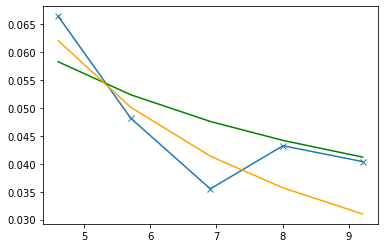

In [8]:
rng = np.random.default_rng(1)
X = get_data(data_type="NETFLIX", len_signal = 10**4)
atoms = X[0]
signals = X[1]
ds = [100, 300, 1000, 3000, 10000]
seeds = 10
diffs = np.zeros((len(ds), seeds))
for seed in range(seeds):
    for d_idx,d in enumerate(ds):
        subset_indices = rng.choice(10000, d, replace=False)
        atoms_subset, signals_subset = atoms[:, subset_indices], signals[:, subset_indices]
        inner_prods = atoms_subset @ signals_subset.T
        max_ = inner_prods.max()
        second_max = np.partition(inner_prods.flatten(), -2)[-2]
        diffs[d_idx][seed] = ((max_ - second_max) / d)
plt.plot(np.log(ds), diffs.mean(axis=1), marker='x')
plt.plot(np.log(ds), 1/np.sqrt(np.log(ds))/8, color='green')
plt.plot(np.log(ds), 1/np.log(ds)/3.5, color='orange')

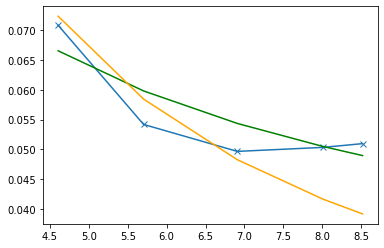

In [11]:
rng = np.random.default_rng(2)
X = get_data(data_type="MOVIE_LENS", len_signal = 5000)
atoms = X[0]
signals = X[1]
ds = [100, 300, 1000, 3000, 5000]
seeds = 10
diffs = np.zeros((len(ds), seeds))
for seed in range(seeds):
    for d_idx,d in enumerate(ds):
        subset_indices = rng.choice(5000, d, replace=False)
        atoms_subset, signals_subset = atoms[:, subset_indices], signals[:, subset_indices]
        inner_prods = atoms_subset @ signals_subset.T
        max_ = inner_prods.max()
        second_max = np.partition(inner_prods.flatten(), -2)[-2]
        diffs[d_idx][seed] = ((max_ - second_max) / d)
plt.plot(np.log(ds), diffs.mean(axis=1), marker='x')
plt.plot(np.log(ds), 1/np.sqrt(np.log(ds))/7, color='green')
plt.plot(np.log(ds), 1/np.log(ds)/3, color='orange')